#### environment: !pip -q install torch torchvision einops

## GET, Summer 26 Project-Diffusion

You will be implementing a DDPM on MNIST dataset, with and without classifier free guidance. Before starting, make sure you have a good understanding of class notes. All notations are from this tutorial: https://arxiv.org/abs/2208.11970 . We follow the epsilon-estimation formulation.

#### What's provided:
We have provided a diffusion denoising U-Net, a diffusion scheduler and helper funcionts, visualization code for conditional and unconditional generation.

#### Items you need to complete:
Some functions in this starter code are incomplete. You will complete those functions and upload the completed code (in `.ipynb` format) to Gradescope. We will test your implementation with custom inputs.  
   You are required to complete the following functions:
   1. DDPM epsilon estimation loss (`ddpm_loss_epsilon()`).
   2. DDPM epsilon estimation loss for classifier free guidance (`ddpm_loss_cfg()`).  
   3. DDPM unconditional sampling`sample_unconditional()`
   4. DDPM sampling with classifer free guidance`sample_conditional()`

We also provide the visualization code for the sampling. You need to write a report about CFG sampling when you tune the gamma parameter.

In [2]:
import math, random, os, numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, utils as vutils
from einops import rearrange

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(0); np.random.seed(0); random.seed(0)

# Data: MNIST to [-1,1], shape (B,1,28,28)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
train_set = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True, num_workers=2, drop_last=True)
num_classes = 10


### DDPM with linear scheduler, you only need to run the code, make sure you can understand the code

In [3]:
# Diffusion schedule
class DiffusionSchedule:
    def __init__(self, T=200, beta_start=1e-4, beta_end=0.02):
        self.T = T
        betas = torch.linspace(beta_start, beta_end, T)
        alphas = 1.0 - betas
        alphas_bar = torch.cumprod(alphas, dim=0)

        self.register(betas, alphas, alphas_bar)

    def register(self, betas, alphas, alphas_bar):
        self.betas = betas.to(device)
        self.alphas = alphas.to(device)
        self.alphas_bar = alphas_bar.to(device)
        self.sqrt_alphas = torch.sqrt(self.alphas)
        self.sqrt_one_minus_alphas = torch.sqrt(1.0 - self.alphas)
        self.sqrt_alphas_bar = torch.sqrt(self.alphas_bar)
        self.sqrt_one_minus_alphas_bar = torch.sqrt(1.0 - self.alphas_bar)
        self.one_over_sqrt_alphas = 1.0 / self.sqrt_alphas

    def sample_timesteps(self, bsz):
        return torch.randint(0, self.T, (bsz,), device=device, dtype=torch.long)

    def q_sample(self, x0, t, eps):
        # x_t = sqrt(alphabar_t) * x0 + sqrt(1-alphabar_t) * eps
        s1 = self.sqrt_alphas_bar[t].view(-1,1,1,1)
        s2 = self.sqrt_one_minus_alphas_bar[t].view(-1,1,1,1)
        return s1 * x0 + s2 * eps

    def posterior_mean_variance(self, xt, eps_pred, t):
        # t: (B,), xt: (B,1,28,28), eps_pred: same shape as xt
        alpha_t      = self.alphas[t].view(-1,1,1,1)
        alpha_bar_t  = self.alphas_bar[t].view(-1,1,1,1)

        # compute alpha_bar_{t-1}; define alpha_bar_{-1}=1 for t=0
        t_prev = torch.clamp(t-1, min=0)
        alpha_bar_prev = self.alphas_bar[t_prev].view(-1,1,1,1)
        alpha_bar_prev = torch.where((t==0).view(-1,1,1,1), torch.ones_like(alpha_bar_prev), alpha_bar_prev)

        beta_t = self.betas[t].view(-1,1,1,1)
        # posterior variance (DDPM)
        beta_tilde_t = ((1 - alpha_bar_prev) / (1 - alpha_bar_t)) * beta_t

        # DDPM ε-prediction mean:
        # mu = 1/sqrt(alpha_t) * (xt - ((1 - alpha_t)/sqrt(1 - alpha_bar_t)) * eps_pred)
        mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

        var = beta_tilde_t
        return mean, var


### Denoising model architecutre, you only need to run the code

In [4]:
import math, torch, torch.nn as nn, torch.nn.functional as F

# sinusoidal time embedding
def sinusoidal_time_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(0, half, device=t.device).float() / half)
    args = t.float().unsqueeze(1) * freqs.unsqueeze(0)
    emb = torch.cat([torch.sin(args), torch.cos(args)], dim=1)
    if dim % 2 == 1:
        emb = F.pad(emb, (0,1))
    return emb

# Adaptive GroupNorm
class AdaGN(nn.Module):
    def __init__(self, num_channels, cond_dim, groups=8):
        super().__init__()
        self.gn = nn.GroupNorm(groups, num_channels, affine=False)
        self.fc = nn.Linear(cond_dim, num_channels * 2)
        nn.init.zeros_(self.fc.weight)
        nn.init.zeros_(self.fc.bias)
    def forward(self, x, cond):
        h = self.gn(x)
        s, b = self.fc(cond).chunk(2, dim=1)
        s = s.unsqueeze(-1).unsqueeze(-1)
        b = b.unsqueeze(-1).unsqueeze(-1)
        return h * (1 + s) + b

# Residual block with AdaGN
class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, cond_dim, dropout=0.0):
        super().__init__()
        self.in_conv = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.ada1 = AdaGN(c_out, cond_dim)
        self.mid_conv = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.ada2 = AdaGN(c_out, cond_dim)
        self.dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        self.out_conv = nn.Conv2d(c_out, c_out, 3, padding=1)
        nn.init.zeros_(self.out_conv.weight)
        nn.init.zeros_(self.out_conv.bias)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, cond):
        h = self.in_conv(x)
        h = F.silu(self.ada1(h, cond))
        h = self.mid_conv(h)
        h = F.silu(self.ada2(h, cond))
        h = self.dropout(h)
        h = self.out_conv(h)
        return F.silu(h + self.skip(x))

class Down(nn.Module):
    def __init__(self, c_in, c_out):
        super().__init__()
        self.conv = nn.Conv2d(c_in, c_out, 3, stride=2, padding=1)
    def forward(self, x):
        return self.conv(x)

class Up(nn.Module):
    def __init__(self, c_in, c_out):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode='nearest')
        self.conv = nn.Conv2d(c_in, c_out, 3, padding=1)
    def forward(self, x):
        return self.conv(self.up(x))

class SmallUNet(nn.Module):
    """
    Improved Small U-Net without attention.
    28x28 -> 14x14 -> 7x7 -> 14x14 -> 28x28
    """
    def __init__(self, num_classes=10, null_class=True, ch=64, t_dim=128, y_dim=128, dropout=0.0):
        super().__init__()
        self.null_id = num_classes if null_class else None
        n_embed = num_classes + (1 if null_class else 0)
        self.class_embed = nn.Embedding(n_embed, y_dim)
        self.t_dim, self.y_dim = t_dim, y_dim
        cond_dim = t_dim + y_dim

        self.inp = nn.Conv2d(1, ch, 3, padding=1)

        # down path
        self.rb1 = ResBlock(ch, ch, cond_dim, dropout)
        self.down1 = Down(ch, ch*2)
        self.rb2 = ResBlock(ch*2, ch*2, cond_dim, dropout)
        self.down2 = Down(ch*2, ch*4)

        # bottleneck
        self.rb_mid1 = ResBlock(ch*4, ch*4, cond_dim, dropout)
        self.rb_mid2 = ResBlock(ch*4, ch*4, cond_dim, dropout)

        # up path
        self.up1 = Up(ch*4, ch*2)
        self.rb_up1 = ResBlock(ch*2 + ch*2, ch*2, cond_dim, dropout)
        self.up2 = Up(ch*2, ch)
        self.rb_up2 = ResBlock(ch + ch, ch, cond_dim, dropout)

        self.out = nn.Conv2d(ch, 1, 3, padding=1)

        # time/class projections
        self.proj_t = nn.Sequential(nn.Linear(t_dim, t_dim*4), nn.SiLU(), nn.Linear(t_dim*4, t_dim))
        self.proj_y = nn.Sequential(nn.Linear(y_dim, y_dim*4), nn.SiLU(), nn.Linear(y_dim*4, y_dim))

    def forward(self, x, t, y):
        t_emb = self.proj_t(sinusoidal_time_embedding(t, self.t_dim))
        if y is not None:
            y_emb = self.class_embed(y)
        else:
            y_emb = torch.zeros(x.size(0), self.y_dim, device=x.device)
        y_emb = self.proj_y(y_emb)
        cond = torch.cat([t_emb, y_emb], dim=1)

        # encoder
        h0 = self.inp(x)
        h1 = self.rb1(h0, cond)
        h2 = self.down1(h1)
        h3 = self.rb2(h2, cond)
        h4 = self.down2(h3)
        h5 = self.rb_mid1(h4, cond)
        h6 = self.rb_mid2(h5, cond)

        # decoder
        u1 = self.up1(h6)
        u1 = torch.cat([u1, h3], dim=1)
        u1 = self.rb_up1(u1, cond)
        u2 = self.up2(u1)
        u2 = torch.cat([u2, h1], dim=1)
        u2 = self.rb_up2(u2, cond)

        eps = self.out(u2)
        return eps


### you need to implement the DDPM loss function

In [5]:
# Losses
sched = DiffusionSchedule(T=200)
net = SmallUNet(num_classes=num_classes, null_class=True, ch=64).to(device)

def ddpm_loss_epsilon(sched, net, x0, y):
    t = sched.sample_timesteps(x0.shape[0])
    eps = torch.randn_like(x0)
    x_t = sched.q_sample(x0, t, eps)
    eps_hat = net(x_t,t,y)
    loss = F.mse_loss(eps_hat,eps)
    """
    TODO (A): Standard ε-prediction DDPM loss.
      
      1) sample t ~ Uniform{0..T-1}
      2) sample eps ~ N(0,I)
      3) build x_t = sqrt(alphabar_t) x0 + sqrt(1-alphabar_t) eps (hint: use sched.q_sample)
      4) predict eps_hat = net(x_t, t, y_cond)  (you may use real labels y here)
      5) MSE between eps_hat and eps
    Return: loss (scalar)
    """
    """Your code here"""
    return loss


def ddpm_loss_cfg(sched, net, x0, y, null_id):
    t = sched.sample_timesteps(x0.shape[0])
    eps = torch.randn_like(x0)
    x_t = sched.q_sample(x0, t, eps)

    eps_hat_cond = net(x_t, t, y)
    y_null = torch.full_like(y, null_id)
    eps_hat_uncond = net(x_t, t, y_null)

    loss = F.mse_loss(eps_hat_cond, eps) + F.mse_loss(eps_hat_uncond, eps)
    """
    TODO (B): CFG training loss (two forward passes).
      Same steps 1-3 as above (ddpm_loss_epsilon), then:
      - eps_hat_cond = net(x_t, t, y)
      - eps_hat_uncond = net(x_t, t, y_null) (unconditional)
      - loss = MSE(eps_hat_cond, eps) + MSE(eps_hat_uncond, eps)
    Return: loss (scalar)
    """
    """Your code here"""
    return loss


### training, you just need to run the code

In [6]:
from tqdm import tqdm
class EMA:
    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.shadow = {k: v.detach().clone() for k, v in model.state_dict().items()}
    def update(self, model):
        with torch.no_grad():
            for k, v in model.state_dict().items():
                self.shadow[k].mul_(self.decay).add_(v.detach(), alpha=1-self.decay)
    def copy_to(self, model):
        model.load_state_dict(self.shadow, strict=True)
ema = EMA(net, decay=0.999)

In [ ]:
# Train
USE_CFG_LOSS = True
epochs = 30  # feel free to increase
opt = torch.optim.AdamW(net.parameters(), lr=1e-4)

net.train()
for epoch in (range(1, epochs+1)):
    for x, y in tqdm(train_loader):
        x = x.to(device)
        y = y.to(device)
        if USE_CFG_LOSS:
            loss = ddpm_loss_cfg(sched, net, x, y, null_id=net.null_id)
        else:
            loss = ddpm_loss_epsilon(sched, net, x, y)
        # print(loss)

        opt.zero_grad()
        loss.backward()
        opt.step()
        ema.update(net)
    print(f"epoch {epoch}: loss={loss.item():.4f}")

ema.copy_to(net); net.eval()

In [7]:
net.load_state_dict(torch.load('trained_model.pth', map_location=device))
net.eval()

/tmp/ipykernel_765810/1172875231.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load('trained_model.pth', map_location=device))


SmallUNet(
  (class_embed): Embedding(11, 128)
  (inp): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (rb1): ResBlock(
    (in_conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (ada1): AdaGN(
      (gn): GroupNorm(8, 64, eps=1e-05, affine=False)
      (fc): Linear(in_features=256, out_features=128, bias=True)
    )
    (mid_conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (ada2): AdaGN(
      (gn): GroupNorm(8, 64, eps=1e-05, affine=False)
      (fc): Linear(in_features=256, out_features=128, bias=True)
    )
    (dropout): Identity()
    (out_conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (skip): Identity()
  )
  (down1): Down(
    (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  )
  (rb2): ResBlock(
    (in_conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (ada1): AdaGN(
      (gn): GroupNorm(8, 128, eps=1e-05, affine=False

### Implement the samplers: (you need to implement a few lines of code inside sample_unconditional and sample_conditional)

In [16]:
# Samplers
@torch.no_grad()
def sample_unconditional(n=64, steps=None):
    net.eval()
    T = sched.T if steps is None else steps
    x = torch.randn(n, 1, 28, 28, device=device)
    y_null = torch.full((n,), net.null_id, device=device, dtype=torch.long)

    for ti in reversed(range(T)):
        t = torch.full((n,), ti, device=device, dtype=torch.long)

        eps_hat = net(x, t, y_null)
        mu, var = sched.posterior_mean_variance(x, eps_hat, t)

        if ti > 0:
            x = mu + torch.sqrt(var) * torch.randn_like(x)
        else:
            x = mu
    return x.clamp(-1,1)


@torch.no_grad()
def sample_conditional(label, gamma=3.0, n=64, steps=None):
    net.eval()
    T = sched.T if steps is None else steps
    x = torch.randn(n, 1, 28, 28, device=device)
    y_lab  = torch.full((n,), int(label), device=device, dtype=torch.long)
    y_null = torch.full((n,), net.null_id, device=device, dtype=torch.long)

    for ti in reversed(range(T)):
        t = torch.full((n,), ti, device=device, dtype=torch.long)

        eps_c = net(x, t, y_lab)
        eps_u = net(x, t, y_null)
        eps_hat = (1.0 + gamma) * eps_c - gamma * eps_u

        mu, var = sched.posterior_mean_variance(x, eps_hat, t)

        if ti > 0:
            x = mu + torch.sqrt(var) * torch.randn_like(x)
        else:
            x = mu
    return x.clamp(-1,1)

In [9]:
# Helpers to visualize
def show_grid(x, nrow=8, title=''):
    x = (x.clamp(-1,1) + 1) * 0.5  # to [0,1]
    grid = vutils.make_grid(x, nrow=nrow)
    import matplotlib.pyplot as plt
    plt.figure(figsize=(8,8))
    plt.axis('off')
    if title: plt.title(title)
    plt.imshow(grid.permute(1,2,0).cpu())
    plt.show()


### Unconditional Generation

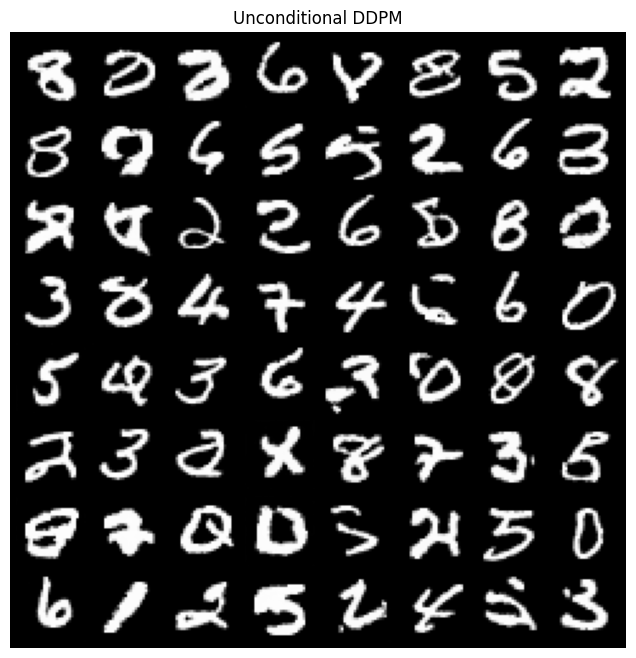

In [12]:
# Unconditional samples
x_un = sample_unconditional(n=64)
show_grid(x_un, title='Unconditional DDPM')

### Conditional Generation with CFG
Tune this gamma and analyze what different gammas represent. Write a report about this with gamma = [-1, 0, 1, 2, 3, 4, 5]. Show generated images with different gamma and explain the images.

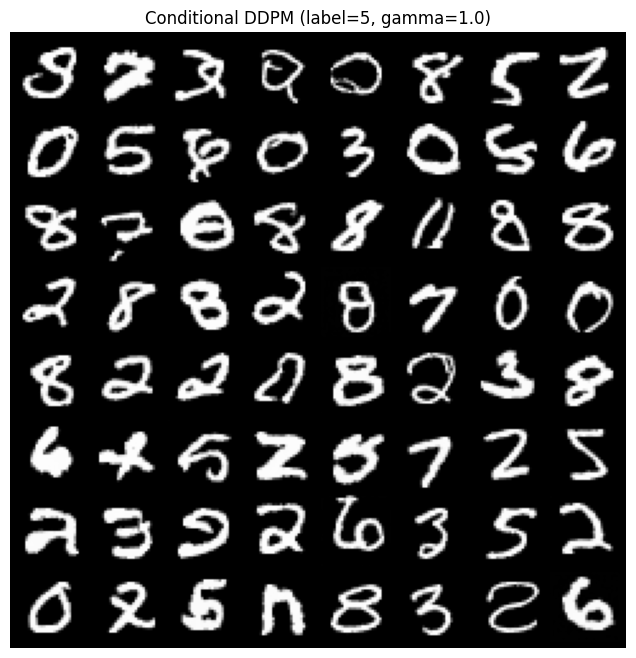

In [13]:
# Conditional samples for a digit
x_c5 = sample_conditional(label=2, gamma=-1, n=64)
show_grid(x_c5, title='Conditional DDPM (label=5, gamma=1.0)')

### Code the exploratory parts below

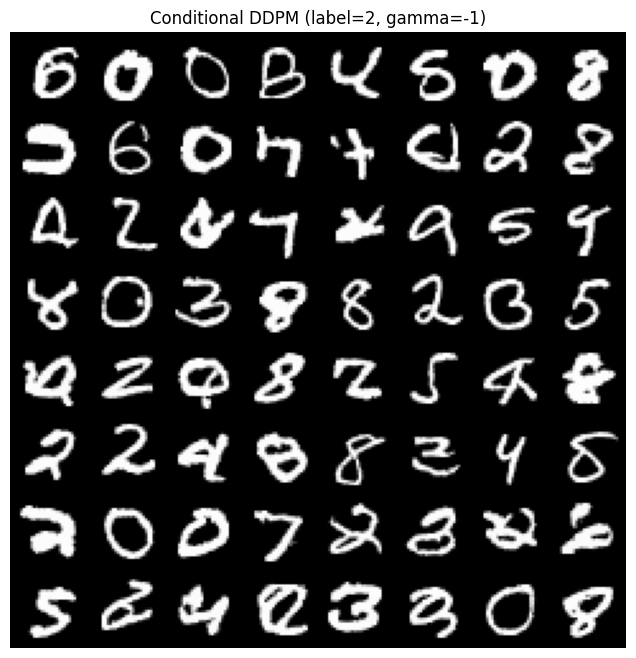

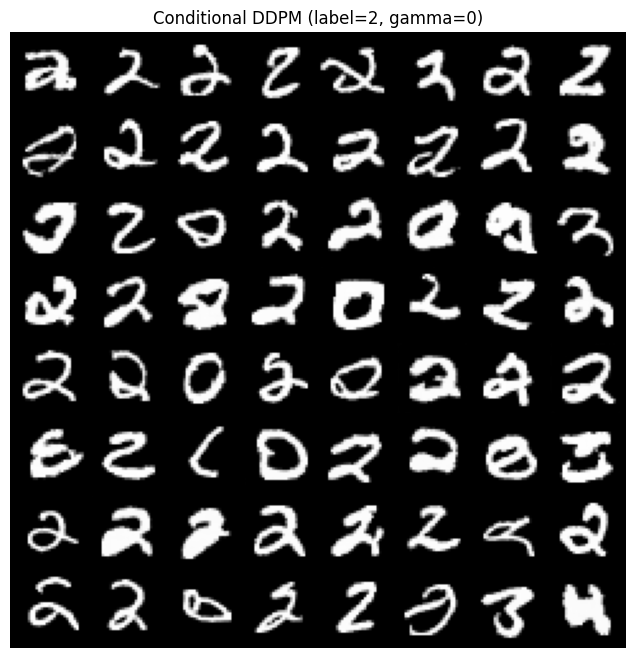

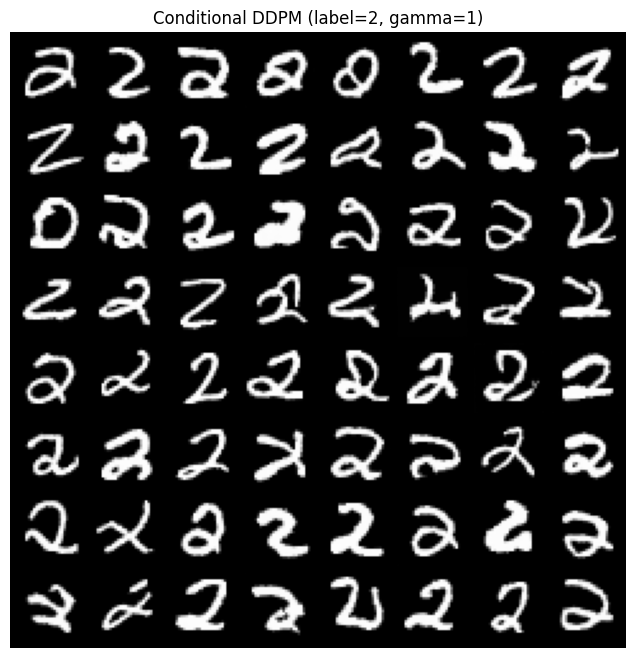

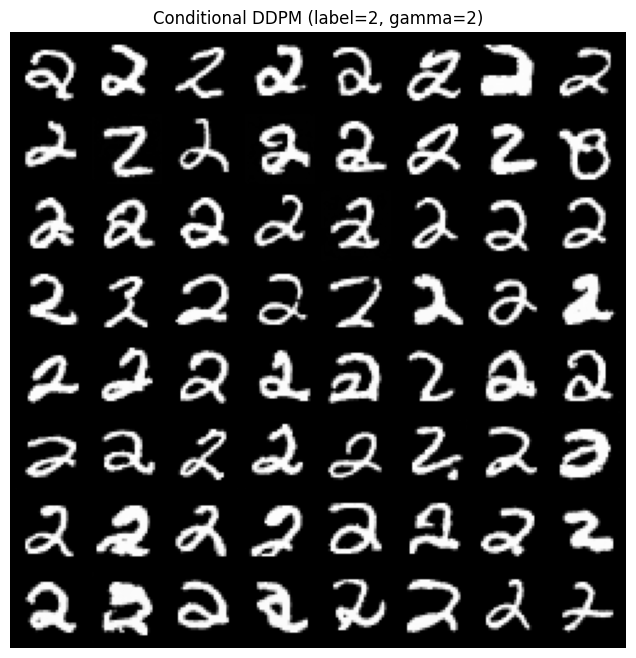

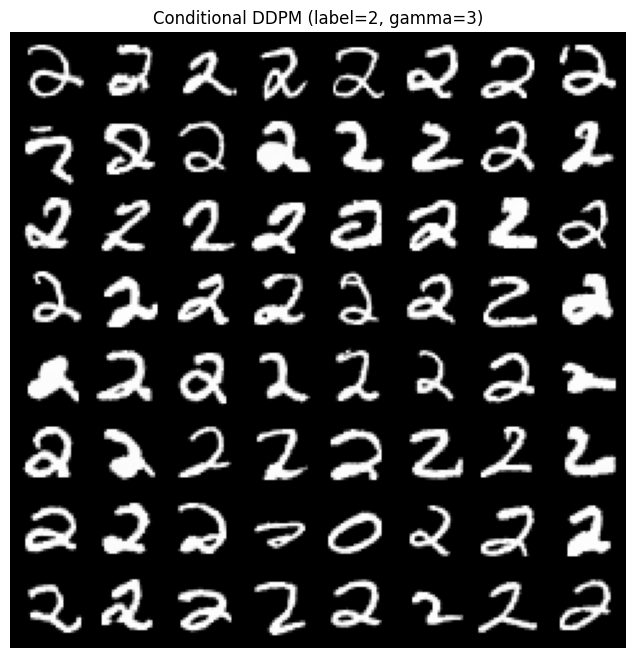

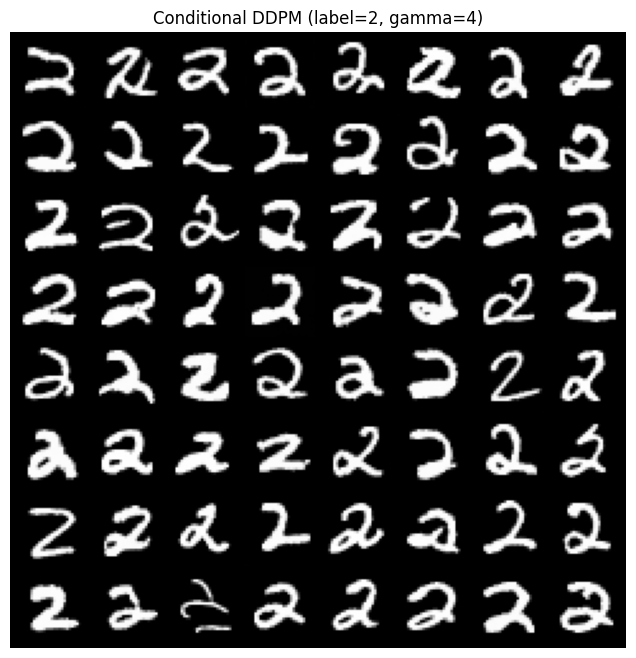

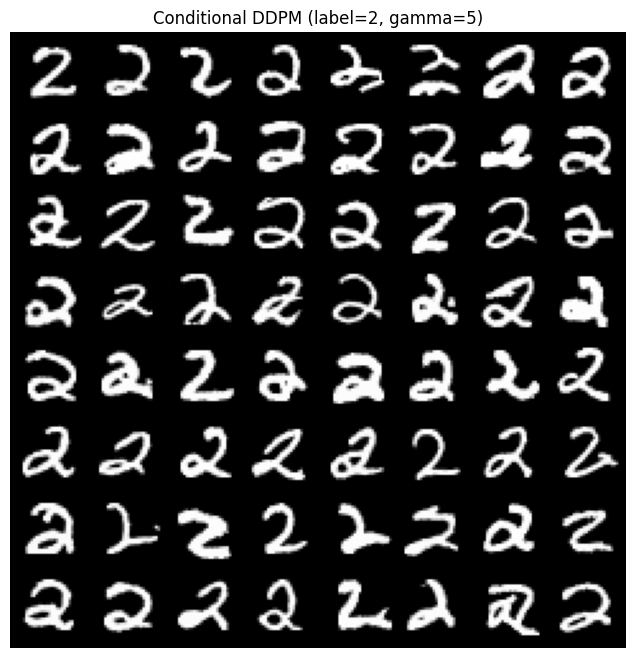

In [14]:
for gamma in [-1, 0, 1, 2, 3, 4, 5]:
    x_c = sample_conditional(label=2, gamma=gamma, n=64)
    show_grid(x_c, title=f'Conditional DDPM (label=2, gamma={gamma})')

In [18]:
@torch.no_grad()
def sample_unconditional_from(x_t, t_start):
    net.eval()
    x = x_t.clone()
    n = x.shape[0]
    y_null = torch.full((n,), net.null_id, device=device, dtype=torch.long)

    for ti in reversed(range(t_start + 1)):
        t = torch.full((n,), ti, device=device, dtype=torch.long)

        eps_hat = net(x, t, y_null)
        mu, var = sched.posterior_mean_variance(x, eps_hat, t)

        if ti > 0:
            x = mu + torch.sqrt(var) * torch.randn_like(x)
        else:
            x = mu
    return x.clamp(-1, 1)


@torch.no_grad()
def sample_conditional_from(x_t, t_start, label, gamma=3.0):
    net.eval()
    x = x_t.clone()
    n = x.shape[0]
    y_lab  = torch.full((n,), int(label), device=device, dtype=torch.long)
    y_null = torch.full((n,), net.null_id, device=device, dtype=torch.long)

    for ti in reversed(range(t_start + 1)):
        t = torch.full((n,), ti, device=device, dtype=torch.long)

        eps_c = net(x, t, y_lab)
        eps_u = net(x, t, y_null)
        eps_hat = (1.0 + gamma) * eps_c - gamma * eps_u

        mu, var = sched.posterior_mean_variance(x, eps_hat, t)

        if ti > 0:
            x = mu + torch.sqrt(var) * torch.randn_like(x)
        else:
            x = mu
    return x.clamp(-1, 1)

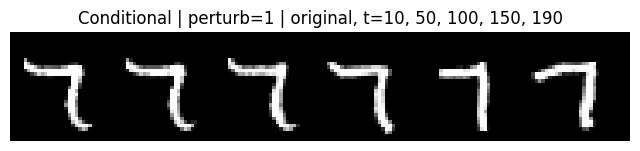

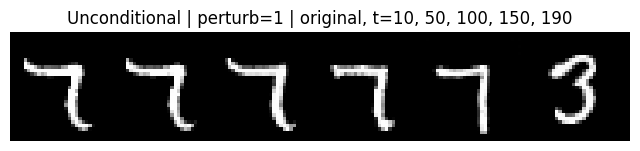

In [21]:
T_LIST = [10, 50, 100, 150, 190]
REL = 1    # 그 t의 노이즈 크기 대비 70%만큼 흔들기

x0_7 = sample_conditional(label=7, gamma=3.0, n=1)

perturbed = []
for ts in T_LIST:
    t_ten = torch.full((1,), ts, device=device, dtype=torch.long)
    x_t   = sched.q_sample(x0_7, t_ten, torch.randn_like(x0_7))
    scale = REL * sched.sqrt_one_minus_alphas_bar[ts].item()
    perturbed.append(x_t + scale * torch.randn_like(x_t))

row_c = [x0_7] + [sample_conditional_from(p, ts, label=7, gamma=3.0)
                  for p, ts in zip(perturbed, T_LIST)]
show_grid(torch.cat(row_c), nrow=6,
          title=f'Conditional | perturb={REL} | original, t=10, 50, 100, 150, 190')

row_u = [x0_7] + [sample_unconditional_from(p, ts)
                  for p, ts in zip(perturbed, T_LIST)]
show_grid(torch.cat(row_u), nrow=6,
          title=f'Unconditional | perturb={REL} | original, t=10, 50, 100, 150, 190')

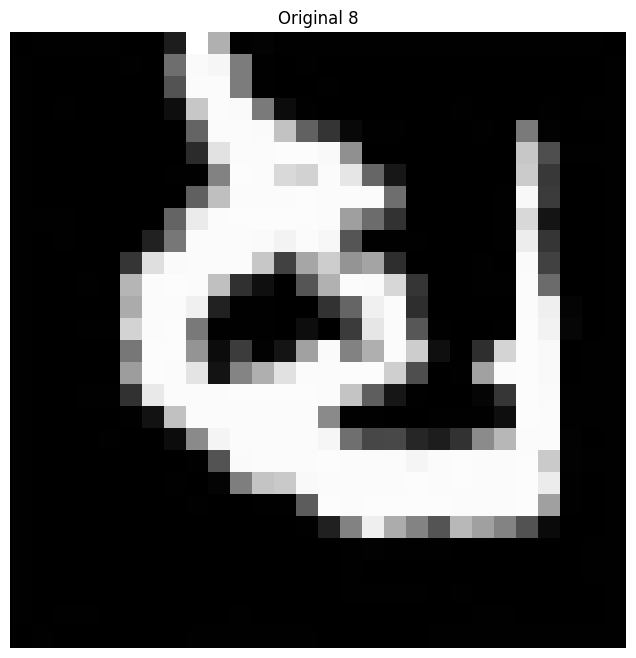

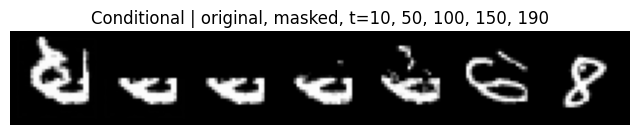

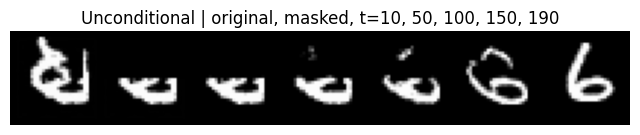

In [72]:
T_LIST = [10, 50, 100, 150, 190]

# --- 1. 원본 "8" ---
x0_8 = sample_conditional(label=8, gamma=3.0, n=1)
show_grid(x0_8, title='Original 8')      # 8처럼 안 나오면 이 셀 다시 실행

# --- 2. 위쪽 절반 마스킹 ---
x0_m = x0_8.clone()
x0_m[:, :, :14, :] = -1.0                # 0~13행을 배경(-1)으로 덮음

# --- 3. t별 노이즈화 (두 그림이 공유) ---
noisy = []
for ts in T_LIST:
    t_ten = torch.full((1,), ts, device=device, dtype=torch.long)
    noisy.append(sched.q_sample(x0_m, t_ten, torch.randn_like(x0_m)))

# --- 4. 9장용 사진 (conditional) ---
row_c = [x0_8, x0_m] + [sample_conditional_from(x, ts, label=8, gamma=3.0)
                        for x, ts in zip(noisy, T_LIST)]
show_grid(torch.cat(row_c), nrow=7,
          title='Conditional | original, masked, t=10, 50, 100, 150, 190')

# --- 5. 10장용 사진 (unconditional) ---
row_u = [x0_8, x0_m] + [sample_unconditional_from(x, ts)
                        for x, ts in zip(noisy, T_LIST)]
show_grid(torch.cat(row_u), nrow=7,
          title='Unconditional | original, masked, t=10, 50, 100, 150, 190')